<a href="https://colab.research.google.com/github/k-nikhil-coder/100-day-ai-engineer/blob/main/Day07_Titanic_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Fetching Titanic dataset...

--- Quick Overview ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None

--- Missing Values Count ---
Age         177
Cabin       687
Embarked      2
dtype: int64


/tmp/ipykernel_697/2085205545.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


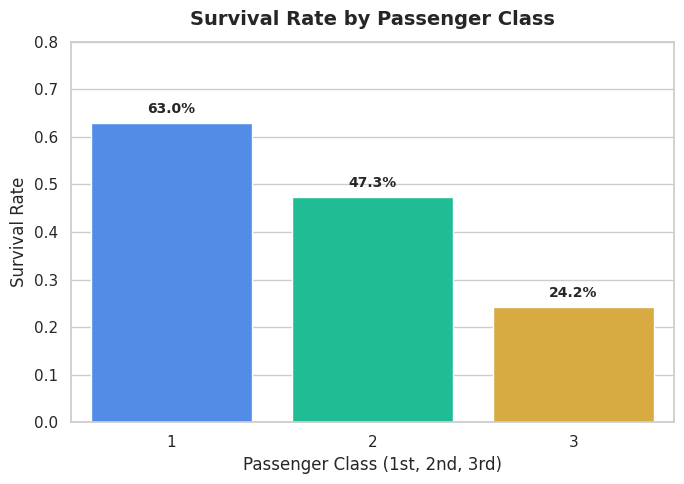

/tmp/ipykernel_697/2085205545.py:81: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


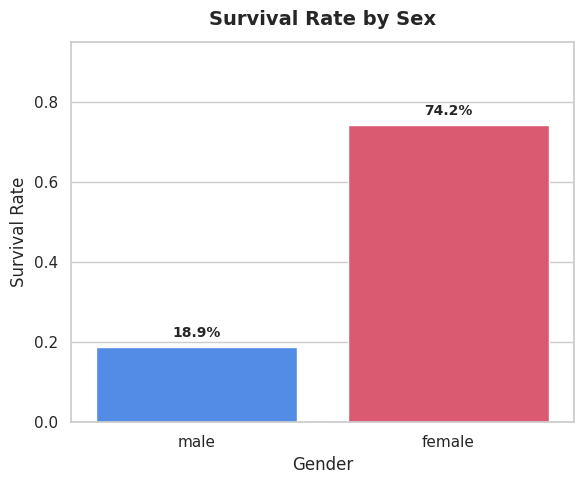

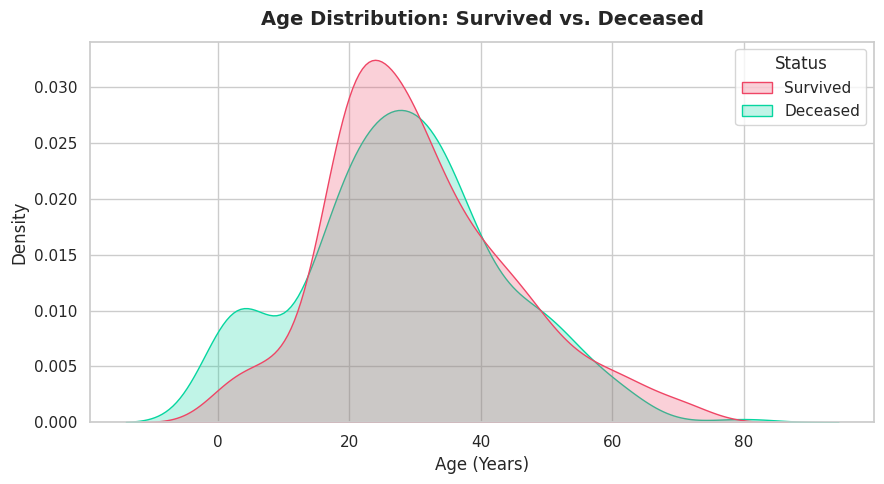

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ==========================================
# 1. Global Setup & Plot Styling
# ==========================================
sns.set_theme(style='whitegrid', palette='muted')

# Custom palette definitions for consistency across charts
COLOR_SURVIVED = '#06d6a0'  # Soft Teal/Green
COLOR_DECEASED = '#ef4565'  # Soft Red/Coral
PCLASS_COLORS = ['#3a86ff', '#06d6a0', '#f0b429']
GENDER_COLORS = ['#3a86ff', '#ef4565']


def annotate_bars(ax):
    """Utility helper to add percentage labels above bar charts cleanly."""
    for bar in ax.patches:
        height = bar.get_height()
        ax.annotate(
            f'{height:.1%}',  # formatted to 1 decimal place (e.g., 62.9%)
            (bar.get_x() + bar.get_width() / 2.0, height),
            ha='center',
            va='bottom',
            xytext=(0, 5),
            textcoords='offset points',
            fontweight='bold',
            fontsize=10,
        )


# ==========================================
# 2. Data Loading & Inspection
# ==========================================
DATA_URL = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'

print('Fetching Titanic dataset...')
df = pd.read_csv(DATA_URL)

print('\n--- Quick Overview ---')
print(df.info())

print('\n--- Missing Values Count ---')
missing_summary = df.isnull().sum()
print(missing_summary[missing_summary > 0])


# ==========================================
# 3. Exploratory Visualizations
# ==========================================

# Chart 1: Class vs Survival Rate
fig, ax1 = plt.subplots(figsize=(7, 5))

sns.barplot(
    data=df,
    x='Pclass',
    y='Survived',
    errorbar=None,  # Modern seaborn syntax (replaces legacy ci=None)
    palette=PCLASS_COLORS,
    ax=ax1,
)

ax1.set_title(
    'Survival Rate by Passenger Class', fontsize=14, pad=12, fontweight='bold'
)
ax1.set_xlabel('Passenger Class (1st, 2nd, 3rd)')
ax1.set_ylabel('Survival Rate')
ax1.set_ylim(0, 0.8)  # Leave headroom for bar labels

annotate_bars(ax1)
plt.tight_layout()
plt.show()


# Chart 2: Gender vs Survival Rate
fig, ax2 = plt.subplots(figsize=(6, 5))

sns.barplot(
    data=df,
    x='Sex',
    y='Survived',
    errorbar=None,  # Modern seaborn syntax
    palette=GENDER_COLORS,
    ax=ax2,
)

ax2.set_title('Survival Rate by Sex', fontsize=14, pad=12, fontweight='bold')
ax2.set_xlabel('Gender')
ax2.set_ylabel('Survival Rate')
ax2.set_ylim(0, 0.95)

annotate_bars(ax2)
plt.tight_layout()
plt.show()


# Chart 3: Age Distribution by Survival Outcome
fig, ax3 = plt.subplots(figsize=(9, 5))

sns.kdeplot(
    data=df,
    x='Age',
    hue='Survived',
    common_norm=False,
    fill=True,
    palette=[COLOR_DECEASED, COLOR_SURVIVED],
    ax=ax3,
)

ax3.set_title(
    'Age Distribution: Survived vs. Deceased',
    fontsize=14,
    pad=12,
    fontweight='bold',
)
ax3.set_xlabel('Age (Years)')
ax3.set_ylabel('Density')

# Replace numeric legend labels (0, 1) with meaningful strings
handles = ax3.get_legend().legend_handles
ax3.legend(
    handles=handles,
    labels=['Survived', 'Deceased'],
    title='Status',
    loc='upper right',
)

plt.tight_layout()
plt.show()